SIBIL Midplane Mapper — Configuration Summary
  G-file         : ../g184016.03200  [OK]
  Geometry file  : ../baserun/HvsD_Dmesh_noC_v1.v001.geo  [OK]
  B-grid file    : Shelf_new_grid2_sinks2_gradfix/d3d_shelf_184016.03200_nc3.grd.nc  [OK]
  b2fstate       : b2fstate  [OK]
  b2fplasmf      : b2fplasmf  [OK]
  b2fgmtry       : b2fgmtry  [OK]

  Softmax scales (max, min):
    ni  : max=1e+16, min=1e+15
    ne  : max=1e+16, min=1e+15
    Ti  : max=0.5, min=0.0001
    Te  : max=0.5, min=0.0001
SIBIL Succsessfully Imported


/global/homes/b/btaczak/.conda/envs/bout-data/lib/python3.13/site-packages/boutdata/data.py:765: AlwaysWarning: While building x, y, z coordinate arrays, an exception occured: [Errno 2] No such file or directory: '"d3d_shelf_184016.03200_nc3.grd.nc"'
Evaluating non-scalar options not available
  alwayswarn(


Extracted 42 values:
[-0.0349   -0.0325   -0.0279   -0.0238   -0.0201   -0.0167   -0.0138
 -0.0111   -0.00884  -0.00685  -0.00514  -0.00369  -0.00249  -0.00152
 -0.000753 -0.000184  0.000184  0.000484  0.000855  0.0013    0.00182
  0.00243   0.00311   0.00388   0.00474   0.00569   0.00674   0.00789
  0.00914   0.0105    0.012     0.0136    0.0153    0.0171    0.019
  0.0211    0.0233    0.0256    0.0281    0.0307    0.0335    0.0349  ]
Saved plot to /global/cfs/projectdirs/m4491/btaczak/SIBIL-runs/testing/0_iteration/midplane_profiles.png


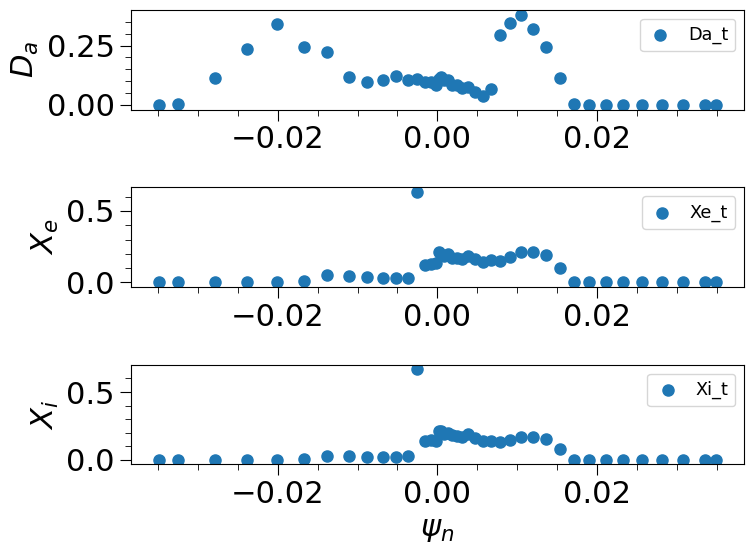

In [1]:
import os
import sys
import yaml
import numpy as np
from pathlib import Path
import re
import numpy as np
import netCDF4 as nc
import yaml
from scipy.interpolate import interp1d
from boutdata.data import BoutData
from boututils.datafile import DataFile
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.ticker import FormatStrFormatter
from boutdata.data import BoutData
sys.path.append("../../helper_scripts")
from sibil_io_functions import load_config, sibil_config_summary, confirm, parse_tdata2, parse_block_sizes, write_updated_namelist, _format_value, extract_tdata_first_index, interpolate_dataset, get_midplane_distances_from_psin, vec_summary, set_tdata2_block, get_all_midplane_distances
from converged_profile_functions import converged_variable

DEFAULT_CONFIG_PATH = "SIBIL_config.yaml"

config_path = DEFAULT_CONFIG_PATH

if not os.path.exists(config_path):
    print(f"Error: config file not found: {config_path}")
    sys.exit(1)

config = load_config(config_path)
sibil_config_summary(config)

# if not confirm():
#     print("Aborted. No changes made.")
#     sys.exit(0)

import sibil  # imported here so summary/confirmation works without dependency installed

# Matches any tdata(i, j, k, l) = value — tolerates arbitrary whitespace.
_TDATA_RE = re.compile(
    r"(tdata\(\s*(\d+)\s*,\s*(\d+)\s*,\s*(\d+)\s*,\s*(\d+)\s*\)\s*=\s*)"
    r"([+-]?\d+(?:\.\d*)?(?:[eE][+-]?\d+)?)",
    re.IGNORECASE,
)

# Matches ndata(1, k, l) = N  — used to discover block sizes and identifiers.
_NDATA_RE = re.compile(
    r"ndata\(\s*1\s*,\s*(\d+)\s*,\s*(\d+)\s*\)\s*=\s*(\d+)",
    re.IGNORECASE,
)

INPUT_FILE  = f"{config["base_path"]}/{config["iteration"]}_iteration/b2.transport.inputfile"
OUTPUT_FILE = f"{config["base_path"]}/{int(config["iteration"])+1}_iteration/b2.transport.inputfile"
bout_dir  = Path(f"{config["base_path"]}/{config["iteration"]}_iteration/Shelf_new_grid2_sinks2_gradfix")
data_dir  = bout_dir / "numpy"
grid_fname= bout_dir / "d3d_shelf_184016.03200_nc3.grd.nc"
grid_fname = str(grid_fname)
d = BoutData(path=bout_dir)

grid = DataFile(grid_fname)
try:
    _ = grid["psi_bdry"]
    has_psi_bdry = True
except Exception:
    has_psi_bdry = False
    
if has_psi_bdry:
    psi_bndry = grid["psi_bdry"]
else:
    psi_bndry = grid["psi_bndry"]

jomp = 44
psi_midplane = grid["psixy"][:,jomp]
psin_midplane = ((grid["psixy"] - grid["psi_axis"]) / (psi_bndry - grid["psi_axis"]))[:,jomp]


vars_to_plot_list = ["Da_t","Xe_t","Xi_t"]
vars_to_plot_averaged = {}
N = 100
l = 130
for var_name in vars_to_plot_list:
    vars_to_plot_averaged[var_name] = converged_variable(data_dir,var_name, N, l)

values = extract_tdata_first_index(INPUT_FILE)
print(f"Extracted {len(values)} values:")
print(values)

psin_mid, distances = get_all_midplane_distances(grid_fname)

outputs = interpolate_dataset(distances,vars_to_plot_averaged['Da_t'][:,jomp,-1],values)
nan_mask = np.isnan(outputs)
outputs[nan_mask]=0

# PLOTTING
rows = len(vars_to_plot_averaged)
fig, axs = plt.subplots(rows,1, figsize=(8,6))
for i, var in enumerate(vars_to_plot_list):
    profile = interpolate_dataset(distances,vars_to_plot_averaged[f'{var}'][:,jomp,-1],values)
    nan_mask = np.isnan(profile)
    profile[nan_mask]=0
    transport_coeff = var.split("_")[0]
    ylabel = f"{transport_coeff[:-1]}_{transport_coeff[-1]}"
    axs[i].scatter(values,profile/np.linalg.norm(profile),label=f"{var}")
    axs[i].set_ylabel(f"${ylabel}$")
    axs[i].legend(fontsize="xx-small", handlelength=1.5)
    if i == rows-1:
        axs[i].set_xlabel(r"${\psi}_n$")

fig.tight_layout()

outpath = f"{config["base_path"]}/{config["iteration"]}_iteration/{config["to_bout_plot"]}"
fig.savefig(outpath, dpi=100)
print(f"Saved plot to {outpath}")
#plt.close()